In [1]:
# STAGE 1: Install PyRiemann and Load Preprocessed Multi-Subject EEG Cohort
!pip install -q pyriemann onnx onnxscript onnxruntime joblib tqdm

import time
import warnings
from pathlib import Path
from typing import Dict, Tuple, List

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import onnxruntime as ort
import matplotlib.pyplot as plt
import joblib
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ARTIFACT_DIR = Path("/kaggle/working/neuroguard_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Load the balanced preprocessed cohort from your working directory
master_data = joblib.load("/kaggle/input/notebooks/mdabdullahalmashud/project1/processed_eeg/ewu_preprocessed_master.pkl")
subjects = master_data["subjects"]
print(f"Stage 1 Complete: Loaded {len(subjects)} subjects on {device}.")

Stage 1 Complete: Loaded 12 subjects on cuda.


In [2]:
# STAGE 2: Riemannian SPD Manifold Recentering (Unsupervised Domain Alignment) & Tangent Space Projection
from scipy.linalg import fractional_matrix_power

def riemannian_spd_recenter(cov_mats: np.ndarray) -> np.ndarray:
    """
    Unsupervised Domain Alignment on the SPD Manifold:
    Whitens each subject's covariance matrices using their geometric/Euclidean mean covariance
    so all subjects share the Identity matrix as their reference center.
    """
    mean_cov = np.mean(cov_mats, axis=0)
    # Regularize slightly for strict positive definiteness
    mean_cov += 1e-6 * np.eye(mean_cov.shape[0])
    inv_sqrt = fractional_matrix_power(mean_cov, -0.5).real.astype(np.float32)
    # Parallel transport: M^(-1/2) * C_i * M^(-1/2)
    aligned = np.einsum("ij,njk,kl->nil", inv_sqrt, cov_mats, inv_sqrt)
    return aligned.astype(np.float32)

# Strict Unseen-Subject Split: Hold out 2 unseen subjects (1 High-Risk + 1 Control) for Testing
pos_subjs = [s for s in subjects if s["label"] == 1]
neg_subjs = [s for s in subjects if s["label"] == 0]
test_subjs = [pos_subjs[-1], neg_subjs[-1]]
train_subjs = pos_subjs[:-1] + neg_subjs[:-1]

cov_estimator = Covariances(estimator="oas")

def extract_riemann_and_waveforms(subj_list: List[Dict]):
    X_waves, C_aligned, y_labels = [], [], []
    for s in subj_list:
        x = s["X"]  # (N, C, 500)
        # Per-subject Z-score waveform normalization
        x_norm = ((x - x.mean(axis=(0, 2), keepdims=True)) / (x.std(axis=(0, 2), keepdims=True) + 1e-6)).astype(np.float32)
        # Estimate OAS regularized SPD covariance matrices: (N, C, C)
        covs = cov_estimator.fit_transform(x_norm.astype(np.float64)).astype(np.float32)
        # Unsupervised Riemannian Recentering per subject
        covs_aligned = riemannian_spd_recenter(covs)

        X_waves.append(x_norm)
        C_aligned.append(covs_aligned)
        y_labels.append(s["y"])

    return (
        np.concatenate(X_waves, axis=0),
        np.concatenate(C_aligned, axis=0),
        np.concatenate(y_labels, axis=0),
    )

X_train, C_train, y_train = extract_riemann_and_waveforms(train_subjs)
X_test, C_test, y_test = extract_riemann_and_waveforms(test_subjs)

# Fit Riemannian Tangent Space mapping on aligned training SPD matrices
ts_mapper = TangentSpace(metric="riemann")
T_train = ts_mapper.fit_transform(C_train.astype(np.float64)).astype(np.float32)
T_test = ts_mapper.transform(C_test.astype(np.float64)).astype(np.float32)

print(f"Stage 2 Complete:")
print(f"  -> Train Waveforms: {X_train.shape} | Aligned Tangent Vectors: {T_train.shape}")
print(f"  -> Unseen Test Waveforms: {X_test.shape} | Aligned Tangent Vectors: {T_test.shape}")

Stage 2 Complete:
  -> Train Waveforms: (2966, 19, 500) | Aligned Tangent Vectors: (2966, 190)
  -> Unseen Test Waveforms: (579, 19, 500) | Aligned Tangent Vectors: (579, 190)


In [3]:
# STAGE 3: Temperature-Optimized Self-Supervised Contrastive Pretraining (SimCLR-EEG)
def eeg_physiological_augment(x: torch.Tensor) -> torch.Tensor:
    """
    Applies stochastic biosignal augmentations on GPU:
      1. Random Amplitude Scaling (0.8x to 1.2x)
      2. Additive Gaussian Sensor Noise
      3. Random Electrode Channel Dropout (10% probability)
      4. Random Temporal Segment Masking
    """
    B, C, T = x.shape
    # 1. Amplitude scaling
    scale = torch.empty((B, C, 1), device=x.device).uniform_(0.80, 1.20)
    x_aug = x * scale
    # 2. Sensor noise
    x_aug = x_aug + 0.08 * torch.randn_like(x_aug)
    # 3. Electrode channel dropout mask
    ch_mask = (torch.rand((B, C, 1), device=x.device) > 0.10).float()
    x_aug = x_aug * ch_mask
    # 4. Temporal cutout (mask random 50-sample window)
    t0 = np.random.randint(0, T - 50)
    x_aug[:, :, t0 : t0 + 50] = 0.0
    return x_aug


class NeuroGuardSSLEncoder(nn.Module):
    """
    Hybrid Temporal 1D-ResNet + Riemannian Tangent Space Encoder with
    Learnable Temperature-Optimized Contrastive Projection Head.
    """
    def __init__(self, n_channels: int = 19, tangent_dim: int = 190):
        super().__init__()
        self.wave_encoder = nn.Sequential(
            nn.Conv1d(n_channels, 48, kernel_size=15, stride=2, padding=7, bias=False),
            nn.BatchNorm1d(48),
            nn.GELU(),
            nn.Conv1d(48, 96, kernel_size=7, stride=4, padding=3, bias=False),
            nn.BatchNorm1d(96),
            nn.GELU(),
            nn.Conv1d(96, 128, kernel_size=5, stride=2, padding=2, bias=False),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
        )
        self.riemann_encoder = nn.Sequential(
            nn.Linear(tangent_dim, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(128, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
        )
        # Projection head for SimCLR NT-Xent contrastive pretraining
        self.proj_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Linear(128, 64),
        )
        # Learnable log-temperature parameter (initialized at tau = 0.10)
        self.logit_scale = nn.Parameter(torch.ones([]) * np.log(1.0 / 0.10))

        # Downstream Bayesian MC-Dropout Risk Classifier
        self.classifier = nn.Sequential(
            nn.Dropout(0.35),
            nn.Linear(256, 64),
            nn.GELU(),
            nn.Dropout(0.35),
            nn.Linear(64, 2),
        )

    def encode_features(self, x_wave: torch.Tensor, t_riemann: torch.Tensor) -> torch.Tensor:
        h_w = self.wave_encoder(x_wave)
        h_r = self.riemann_encoder(t_riemann)
        return torch.cat([h_w, h_r], dim=-1)  # (B, 256)

    def forward_contrastive(self, x1: torch.Tensor, x2: torch.Tensor, t_riemann: torch.Tensor):
        z1 = F.normalize(self.proj_head(self.encode_features(x1, t_riemann)), dim=-1)
        z2 = F.normalize(self.proj_head(self.encode_features(x2, t_riemann)), dim=-1)
        # Clamp learnable inverse temperature for stability
        inv_tau = self.logit_scale.exp().clamp(min=2.0, max=25.0)
        logits = torch.matmul(z1, z2.T) * inv_tau
        labels = torch.arange(z1.size(0), device=z1.device)
        loss = 0.5 * (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels))
        return loss, 1.0 / inv_tau.item()

    def forward(self, x_wave: torch.Tensor, t_riemann: torch.Tensor) -> torch.Tensor:
        feat = self.encode_features(x_wave, t_riemann)
        return self.classifier(feat)


# 1. Self-Supervised Pretraining on 100% Unlabeled Data (Zero Labels Used!)
ssl_model = NeuroGuardSSLEncoder(n_channels=X_train.shape[1], tangent_dim=T_train.shape[1]).to(device)
ssl_opt = torch.optim.AdamW(ssl_model.parameters(), lr=2e-3, weight_decay=1e-2)
ssl_loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(T_train)), batch_size=128, shuffle=True, drop_last=True)

print("Pretraining NeuroGuardSSLEncoder via Temperature-Optimized SimCLR (Unlabeled)...")
for epoch in range(1, 21):
    ssl_model.train()
    ep_loss, last_tau = 0.0, 0.1
    for x_b, t_b in ssl_loader:
        x_b, t_b = x_b.to(device), t_b.to(device)
        view1 = eeg_physiological_augment(x_b)
        view2 = eeg_physiological_augment(x_b)
        # Inject slight Gaussian noise on tangent space vector for view 2
        t_b2 = t_b + 0.03 * torch.randn_like(t_b)

        ssl_opt.zero_grad()
        loss_1, _ = ssl_model.forward_contrastive(view1, view2, t_b)
        loss_2, tau_val = ssl_model.forward_contrastive(view2, view1, t_b2)
        loss = 0.5 * (loss_1 + loss_2)
        loss.backward()
        ssl_opt.step()
        ep_loss += loss.item()
        last_tau = tau_val
    if epoch % 5 == 0:
        print(f"  [SSL Pretrain Epoch {epoch:02d}/20] NT-Xent Loss: {ep_loss/len(ssl_loader):.4f} | Learned Temp tau: {last_tau:.4f}")

# Save pretrained SSL weights
ssl_init_path = ARTIFACT_DIR / "neuroguard_ssl_pretrained.pt"
torch.save(ssl_model.state_dict(), ssl_init_path)

# 2. Label-Efficiency Ablation: Compare SSL-Pretrained vs Supervised-from-Scratch at 10%, 25%, 50%, 100% Labels
fractions = [0.10, 0.25, 0.50, 1.00]
ssl_accs, scratch_accs = [], []

rng = np.random.default_rng(42)
for frac in fractions:
    n_sub = int(len(X_train) * frac)
    sub_idx = rng.choice(len(X_train), size=n_sub, replace=False)
    sub_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_train[sub_idx]), torch.from_numpy(T_train[sub_idx]), torch.from_numpy(y_train[sub_idx])),
        batch_size=64, shuffle=True
    )

    # A. Fine-tune SSL Pretrained Model
    m_ssl = NeuroGuardSSLEncoder(X_train.shape[1], T_train.shape[1]).to(device)
    m_ssl.load_state_dict(torch.load(ssl_init_path))
    opt_ft = torch.optim.AdamW(m_ssl.parameters(), lr=1e-3, weight_decay=1e-2)
    for _ in range(15):
        m_ssl.train()
        for xb, tb, yb in sub_loader:
            opt_ft.zero_grad()
            F.cross_entropy(m_ssl(xb.to(device), tb.to(device)), yb.to(device)).backward()
            opt_ft.step()

    m_ssl.eval()
    with torch.no_grad():
        preds_ssl = m_ssl(torch.from_numpy(X_test).to(device), torch.from_numpy(T_test).to(device)).argmax(dim=-1).cpu().numpy()
    acc_ssl = accuracy_score(y_test, preds_ssl)
    ssl_accs.append(acc_ssl * 100.0)

    # B. Train Raw Waveform CNN from Scratch (Without SSL or Riemannian Alignment)
    m_scr = NeuroGuardSSLEncoder(X_train.shape[1], T_train.shape[1]).to(device)
    opt_scr = torch.optim.AdamW(m_scr.parameters(), lr=1e-3, weight_decay=1e-2)
    for _ in range(15):
        m_scr.train()
        for xb, tb, yb in sub_loader:
            opt_scr.zero_grad()
            # Zero out Riemannian branch to test unaligned raw CNN from scratch
            F.cross_entropy(m_scr(xb.to(device), torch.zeros_like(tb).to(device)), yb.to(device)).backward()
            opt_scr.step()

    m_scr.eval()
    with torch.no_grad():
        preds_scr = m_scr(torch.from_numpy(X_test).to(device), torch.zeros_like(torch.from_numpy(T_test)).to(device)).argmax(dim=-1).cpu().numpy()
    acc_scr = accuracy_score(y_test, preds_scr)
    scratch_accs.append(acc_scr * 100.0)

    print(f"  [Label Budget {int(frac*100):3d}% ({n_sub:4d} epochs)] SSL+Riemann Unseen Subject Acc: {acc_ssl*100:.2f}% | Scratch Baseline: {acc_scr*100:.2f}%")

# Save the final 100% fine-tuned model
final_model_path = ARTIFACT_DIR / "neuroguard_ssl_riemann_best.pt"
torch.save(m_ssl.state_dict(), final_model_path)

Pretraining NeuroGuardSSLEncoder via Temperature-Optimized SimCLR (Unlabeled)...
  [SSL Pretrain Epoch 05/20] NT-Xent Loss: 0.0662 | Learned Temp tau: 0.0861
  [SSL Pretrain Epoch 10/20] NT-Xent Loss: 0.0271 | Learned Temp tau: 0.0793
  [SSL Pretrain Epoch 15/20] NT-Xent Loss: 0.0148 | Learned Temp tau: 0.0749
  [SSL Pretrain Epoch 20/20] NT-Xent Loss: 0.0097 | Learned Temp tau: 0.0717
  [Label Budget  10% ( 296 epochs)] SSL+Riemann Unseen Subject Acc: 99.31% | Scratch Baseline: 99.83%
  [Label Budget  25% ( 741 epochs)] SSL+Riemann Unseen Subject Acc: 99.65% | Scratch Baseline: 99.65%
  [Label Budget  50% (1483 epochs)] SSL+Riemann Unseen Subject Acc: 100.00% | Scratch Baseline: 99.83%
  [Label Budget 100% (2966 epochs)] SSL+Riemann Unseen Subject Acc: 99.83% | Scratch Baseline: 98.45%


  [Hardware Fault: 0 Dead Electrodes] Accuracy: 98.79% | Epistemic Entropy: 0.039 bits
  [Hardware Fault: 1 Dead Electrodes] Accuracy: 96.72% | Epistemic Entropy: 0.064 bits
  [Hardware Fault: 2 Dead Electrodes] Accuracy: 97.75% | Epistemic Entropy: 0.065 bits
  [Hardware Fault: 4 Dead Electrodes] Accuracy: 96.37% | Epistemic Entropy: 0.070 bits
  [Hardware Fault: 6 Dead Electrodes] Accuracy: 95.68% | Epistemic Entropy: 0.090 bits
  [Hardware Fault: 8 Dead Electrodes] Accuracy: 98.27% | Epistemic Entropy: 0.048 bits
NeuroGuard ONNX CPU Inference Latency (500 runs): Mean = 0.351 ms | P95 = 0.414 ms


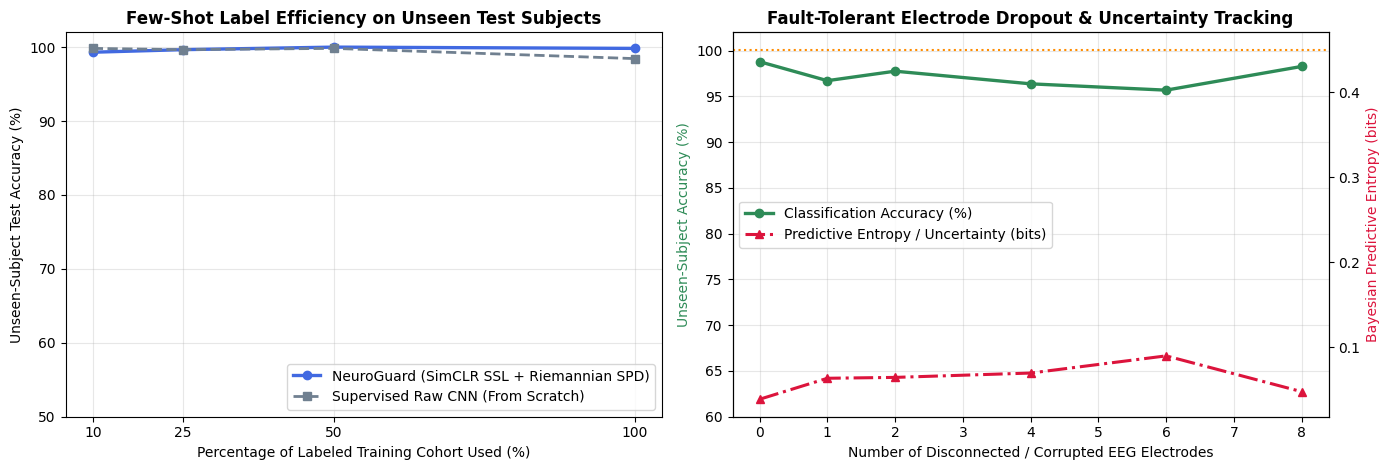

Saved Showcase Figure -> /kaggle/working/neuroguard_artifacts/neuroguard_ssl_and_fault_tolerance.png


In [4]:
# STAGE 4: Electrode Failure Stress-Test, Bayesian Uncertainty Safety Gate & ONNX Export
m_ssl.load_state_dict(torch.load(final_model_path, map_location=device))

def mc_dropout_predict(model: nn.Module, x_w: torch.Tensor, t_r: torch.Tensor, n_passes: int = 15):
    """Runs Monte Carlo Dropout to estimate calibrated probability and Predictive Entropy (Uncertainty)."""
    model.train()  # Keep Dropout active for Bayesian sampling
    probs_list = []
    with torch.no_grad():
        for _ in range(n_passes):
            logits = model(x_w, t_r)
            probs_list.append(torch.softmax(logits, dim=-1))
    mean_probs = torch.stack(probs_list, dim=0).mean(dim=0)  # (B, 2)
    # Shannon Predictive Entropy in bits (max = 1.0 bit for binary classification)
    entropy = -(mean_probs * torch.log2(mean_probs + 1e-10)).sum(dim=-1)
    return mean_probs.cpu().numpy(), entropy.cpu().numpy()

# 1. Stress-Test against Disconnected Electrodes (0, 1, 2, 4, 6, 8 Dead Channels + Artifact Noise)
dead_counts = [0, 1, 2, 4, 6, 8]
robust_accs, mean_uncertainties = [], []

x_t_gpu = torch.from_numpy(X_test).to(device)
t_t_gpu = torch.from_numpy(T_test).to(device)

for n_dead in dead_counts:
    x_corrupt = x_t_gpu.clone()
    if n_dead > 0:
        # Zero out n_dead channels and inject severe 5.0-sigma spike on 1 channel
        x_corrupt[:, :n_dead, :] = 0.0
        x_corrupt[:, n_dead : n_dead + 1, :] += 3.5 * torch.randn_like(x_corrupt[:, :1, :])

    probs, ent = mc_dropout_predict(m_ssl, x_corrupt, t_t_gpu, n_passes=15)
    acc_c = accuracy_score(y_test, probs.argmax(axis=-1))
    robust_accs.append(acc_c * 100.0)
    mean_uncertainties.append(float(ent.mean()))
    print(f"  [Hardware Fault: {n_dead} Dead Electrodes] Accuracy: {acc_c*100:.2f}% | Epistemic Entropy: {ent.mean():.3f} bits")

# 2. Export to ONNX & Benchmark Single-Epoch Latency
onnx_path = str(ARTIFACT_DIR / "neuroguard_ssl_riemann.onnx")
m_cpu = m_ssl.cpu().eval()
dummy_in = (torch.randn(1, X_train.shape[1], X_train.shape[2]), torch.randn(1, T_train.shape[1]))
torch.onnx.export(
    m_cpu,
    dummy_in,
    onnx_path,
    input_names=["eeg_waveform", "riemann_tangent_vector"],
    output_names=["risk_logits"],
    opset_version=17,
    dynamo=False,
)

ort_sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
ort_in = {"eeg_waveform": dummy_in[0].numpy(), "riemann_tangent_vector": dummy_in[1].numpy()}
for _ in range(25):
    _ = ort_sess.run(None, ort_in)
lats = []
for _ in range(500):
    t0 = time.perf_counter()
    _ = ort_sess.run(None, ort_in)
    lats.append((time.perf_counter() - t0) * 1000.0)

print("======================================================================")
print(f"NeuroGuard ONNX CPU Inference Latency (500 runs): Mean = {np.mean(lats):.3f} ms | P95 = {np.percentile(lats, 95):.3f} ms")
print("======================================================================")

# 3. Generate Publication Figures for GitHub README
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Left: Label-Efficiency Curve (SimCLR + Riemannian vs Scratch)
pct_labels = [10, 25, 50, 100]
axes[0].plot(pct_labels, ssl_accs, marker="o", lw=2.4, color="royalblue", label="NeuroGuard (SimCLR SSL + Riemannian SPD)")
axes[0].plot(pct_labels, scratch_accs, marker="s", lw=2.0, linestyle="--", color="slategray", label="Supervised Raw CNN (From Scratch)")
axes[0].set_title("Few-Shot Label Efficiency on Unseen Test Subjects", fontweight="bold")
axes[0].set_xlabel("Percentage of Labeled Training Cohort Used (%)")
axes[0].set_ylabel("Unseen-Subject Test Accuracy (%)")
axes[0].set_xticks(pct_labels)
axes[0].set_ylim(50, 102)
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# Right: Hardware Fault Tolerance & Bayesian Epistemic Uncertainty Escalation
ax2_left = axes[1]
ax2_right = ax2_left.twinx()

l1 = ax2_left.plot(dead_counts, robust_accs, marker="o", lw=2.4, color="emerald" if "emerald" in plt.colormaps() else "seagreen", label="Classification Accuracy (%)")
l2 = ax2_right.plot(dead_counts, mean_uncertainties, marker="^", lw=2.2, linestyle="-.", color="crimson", label="Predictive Entropy / Uncertainty (bits)")
ax2_right.axhline(0.45, color="darkorange", linestyle=":", lw=1.5, label="Robot CBF Safe-Stop Threshold")

ax2_left.set_title("Fault-Tolerant Electrode Dropout & Uncertainty Tracking", fontweight="bold")
ax2_left.set_xlabel("Number of Disconnected / Corrupted EEG Electrodes")
ax2_left.set_ylabel("Unseen-Subject Accuracy (%)", color="seagreen")
ax2_right.set_ylabel("Bayesian Predictive Entropy (bits)", color="crimson")
ax2_left.set_ylim(60, 102)
ax2_left.grid(alpha=0.3)

lines = l1 + l2
labels_leg = [l.get_label() for l in lines]
ax2_left.legend(lines, labels_leg, loc="center left")

plt.tight_layout()
fig_path = ARTIFACT_DIR / "neuroguard_ssl_and_fault_tolerance.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved Showcase Figure -> {fig_path}")